# Bike Share Toronto: dock availability

**An exploratory analytical case study | Ian Lin**  
Data window: September 16 - October 17, 2026. Notebook edition of analysis 1.0.0.

**Question:** Where and when was returning a bicycle difficult in our collected station reports, and what nearby option was observed?

This notebook uses the project's real, frozen GBFS aggregate exports. It is not a trip-demand analysis, a validated forecast, or a live rider trial. The code is executed, not illustrative pseudocode. The PDF/HTML hide some setup and plotting boilerplate; all ten code cells remain available in the executable notebook.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "analysis/portfolio/data/analysis.json").exists()
)
folder = root / "analysis/portfolio/data"
manifest = json.loads((folder / "manifest.json").read_text())
payload = (folder / "analysis.json").read_bytes()
assert hashlib.sha256(payload).hexdigest() == manifest["analysis_json_sha256"]
assert manifest["source_kind"] == "live"
data = json.loads(payload)
q = data["quality"][0]
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})
print("Verified: frozen live-data extract; source hash matches the manifest.")

Verified: frozen live-data extract; source hash matches the manifest.


In [2]:
availability = q["available_reports"] / q["eligible_reports"]
coverage = q["successful_minutes"] / q["expected_minutes"]
summary = pd.Series({
    "Eligible unique reports": f"{q['eligible_reports']:,}",
    "Reports with a dock": f"{q['available_reports']:,}",
    "Observed dock availability": f"{availability:.1%}",
    "Successful poll coverage": f"{coverage:.1%}",
    "Dates with eligible reports": q["observed_days"],
    "Stations represented": q["eligible_stations"]}, name="Result")
display(summary.to_frame())

,Result
Eligible unique reports,"840,283"
Reports with a dock,"790,386"
Observed dock availability,94.1%
Successful poll coverage,3.4%
Dates with eligible reports,11
Stations represented,1075


**Read the two percentages together.** The 94.1% rate describes fresh, operational reports that we actually collected. The 3.4% rate describes collection completeness against the intended one-minute schedule. Neither is prediction accuracy, rider success, or elapsed-time service reliability.

**Decision:** use these results to identify locations worth investigating. Improve collection continuity before making broader operational claims.

<div class="page-break"></div>

## 1. Check collection coverage first

The denominator includes every intended minute, including times when no poll was attempted. Dates and hours are in **America/Toronto**; the first and last dates are partial. No availability is filled across a collection gap.

Successful slots: 1,503 / 44,525
Local dates with no attempted polls: 21


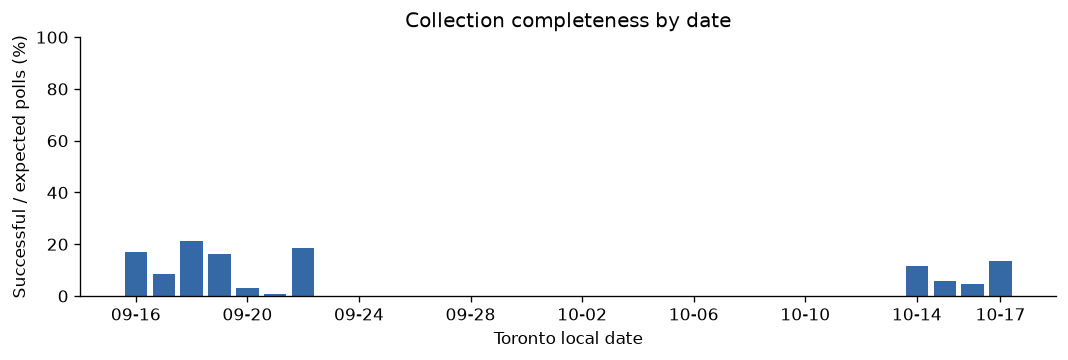

In [3]:
daily = pd.DataFrame(data["daily"])
daily["poll_coverage"] = daily["successful_minutes"] / daily["expected_minutes"]
print(f"Successful slots: {q['successful_minutes']:,} / {q['expected_minutes']:,}")
print(f"Local dates with no attempted polls: {(daily.attempted_minutes == 0).sum()}")
fig, ax = plt.subplots(figsize=(9, 3.1))
ax.bar(range(len(daily)), daily.poll_coverage * 100, color="#3569a5")
ticks = [*range(0, len(daily), 4), len(daily) - 1]
ax.set_xticks(ticks, daily.local_date.str.slice(5).iloc[ticks])
ax.set(
    ylim=(0, 100),
    ylabel="Successful / expected polls (%)",
    xlabel="Toronto local date",
    title="Collection completeness by date",
)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### What the chart shows

- The extract covers 32 local dates, but eligible reports occur on only **11 dates**.
- **21 dates have no attempted polls**; September 23 through October 13 is the longest absent-date span.
- September 16 starts at 14:55 and October 17 ends at 13:00 Toronto time. Other dates use full-day denominators.
- A large number of station rows cannot compensate for missing periods. Gaps are not assumed random.

**Interpretation:** this is a sparse observational sample, not a representative month of service. A successful poll is a collector outcome, not a rider outcome. Partial batches may still contribute valid station reports.

In [4]:
display(
    pd.DataFrame(
        {
            "Poll status": ["Successful", "Partial", "Failed", "Not attempted"],
            "Minute slots": [
                q["successful_minutes"],
                q["partial_minutes"],
                q["failed_minutes"],
                q["expected_minutes"] - q["attempted_minutes"],
            ],
        }
    ).set_index("Poll status")
)

,Minute slots
Poll status,
Successful,1503
Partial,203
Failed,41
Not attempted,42778


<div class="page-break"></div>

## 2. Compare observed station full shares

A full report has **zero reported usable docks**. The support rule requires at least 100 eligible unique reports across five observed dates. It admits 1,067 of 1,075 stations; low-support stations remain in the public data and Excel workbook.

In [5]:
stations = pd.DataFrame(data["stations"])
ranked = stations[stations.ranking_eligible].sort_values(
    ["full_rate", "station_id"], ascending=[False, True]
)
top = ranked.head(6).copy()
top["Full share (%)"] = (100 * top.full_reports / top.reports).round(1)
display(
    top[["station_id", "name", "full_reports", "reports", "Full share (%)"]]
    .rename(
        columns={
            "station_id": "ID",
            "name": "Station",
            "full_reports": "Full",
            "reports": "Eligible",
        }
    )
    .set_index("ID")
)

,Station,Full,Eligible,Full share (%)
ID,,,,
7315,Queen St E / Hammersmith Ave,443,782,56.6
7478,Ellis Ave / The Queensway,416,781,53.3
7471,2300 Lakeshore Blvd W,404,788,51.3
7516,Superior Ave / Lake Shore Blvd W,395,800,49.4
7341,Eastern Ave / Winnifred Ave,386,790,48.9
7220,Lake Shore Blvd W / Ellis Ave,375,786,47.7


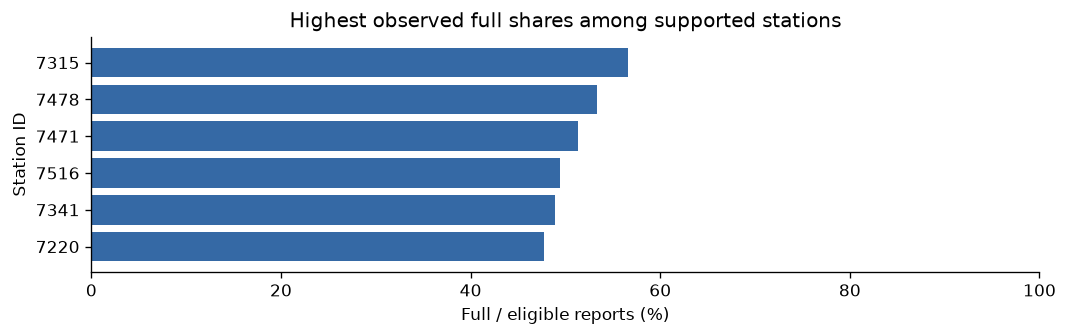

In [6]:
fig, ax = plt.subplots(figsize=(9, 2.9))
ax.barh(top.station_id, top["Full share (%)"], color="#3569a5")
ax.invert_yaxis()
ax.set(
    xlim=(0, 100),
    xlabel="Full / eligible reports (%)",
    ylabel="Station ID",
    title="Highest observed full shares among supported stations",
)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Finding:** station 7315, Queen St E / Hammersmith Ave, was full in **443 / 782 reports (56.6%)**. This makes it a candidate for further observation, not proof that it is one of Toronto's worst stations.

Full share is report-weighted, not time-weighted. Metadata comes from the version attached to each historical snapshot; displayed names are the last eligible observed names. Counts and dates matter when comparing stations. These data cannot establish unmet trip demand or explain rebalancing needs.

<div class="page-break"></div>

## 3. Inspect local-hour patterns cautiously

Compare weekdays and weekends without treating them as matched samples. Each chart cell needs at least **100 reports on three observed dates**. Unsupported cells remain missing, not zero. The underlying export retains all observations.

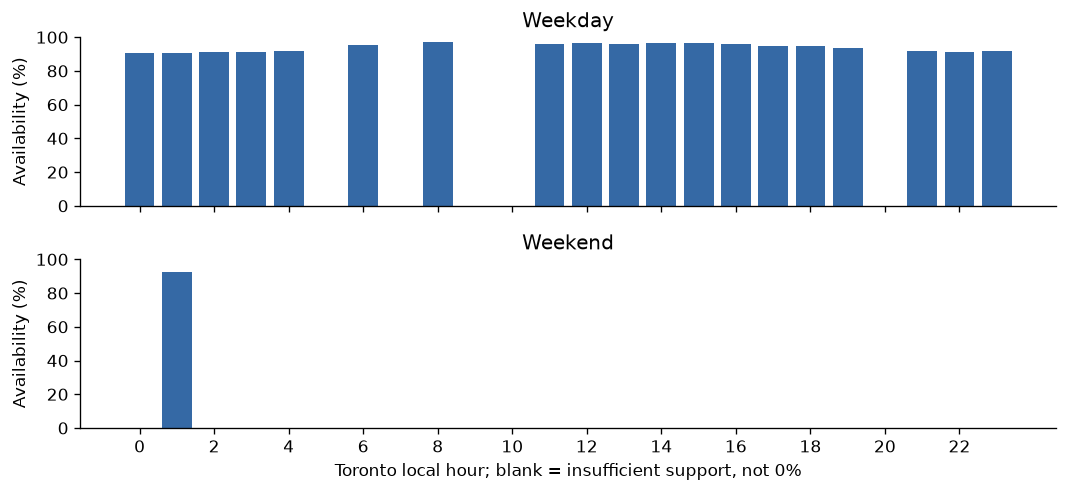

In [7]:
hourly = pd.DataFrame(data["time_patterns"])
supported = (hourly.reports >= 100) & (hourly.observed_days >= 3)
hourly["Availability (%)"] = 100 * hourly.available_reports / hourly.reports
hourly.loc[~supported, "Availability (%)"] = float("nan")
fig, axes = plt.subplots(2, 1, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, day_type in zip(axes, ["Weekday", "Weekend"], strict=True):
    series = hourly[hourly.day_type == day_type].set_index("local_hour")
    values = series["Availability (%)"].reindex(range(24))
    ax.bar(range(24), values, color="#3569a5")
    ax.set(ylim=(0, 100), ylabel="Availability (%)", title=day_type)
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(range(0, 24, 2))
axes[-1].set_xlabel("Toronto local hour; blank = insufficient support, not 0%")
plt.tight_layout()
plt.show()

**The sparse weekend panel is a finding about data coverage.** Most weekend hours lack three observed dates, even when they contain many station reports. Do not interpret blank hours as unavailable docks.

Different dates and station mixes can explain apparent hourly differences. This analysis establishes neither a peak-period causal effect nor a statistically supported weekday/weekend difference. The next step is a comparison of the same stations on well-covered dates, followed by stability checks across independent weeks.

<div class="page-break"></div>

## 4. Examine nearby options and sensitivity

For the ten highest supported full-share stations, the SQL selects the **nearest fresh operational neighbor within 750 m in the same fetched feed**, independently of its dock count. Below are the first three stations in the ranking, not the three best nearby outcomes.

In [8]:
nearby = pd.DataFrame(data["nearby"]).set_index("station_id")
comparison = nearby.loc[ranked.head(3).station_id].copy()
comparison["With dock / matched (%)"] = (
    100 * comparison.nearby_available_reports / comparison.matched_reports
).round(1)
comparison["Mean distance (m)"] = comparison.mean_distance_m.round(0).astype(int)
columns = ["full_reports", "matched_reports", "nearby_available_reports",
           "With dock / matched (%)", "Mean distance (m)"]
labels = {"full_reports": "Full", "matched_reports": "Matched",
          "nearby_available_reports": "With dock"}
display(comparison[columns].rename(columns=labels))

,Full,Matched,With dock,With dock / matched (%),Mean distance (m)
station_id,,,,,
7315,443,442,219,49.5,255
7478,416,416,262,63.0,313
7471,404,404,400,99.0,352


**Interpretation:** station 7471 had a nearest matched neighbor with a dock in **400 / 404 comparisons (99.0%)**. Station 7315 had one unmatched report; its matched comparison was **219 / 442 (49.5%)**, with 443 full reports in total.

Distances are straight-line, not routes. The chosen neighbor can change across observations. Same-feed reports can be up to five minutes old and are not exactly simultaneous physical measurements. These are **not arrival-time forecasts or sequential backup-success rates**: no travel delay, reservation, or effect of a rider on inventory is modeled.

### Does a stricter freshness rule change the aggregate rate?

In [9]:
sensitivity = pd.DataFrame(data["sensitivity"])
sensitivity["Availability (%)"] = (100 * sensitivity.available_reports / sensitivity.reports).round(
    1
)
display(
    sensitivity[["fresh_seconds", "reports", "available_reports", "Availability (%)"]]
    .rename(
        columns={
            "fresh_seconds": "Maximum age (s)",
            "reports": "Eligible",
            "available_reports": "With dock",
        }
    )
    .set_index("Maximum age (s)")
)

,Eligible,With dock,Availability (%)
Maximum age (s),,,
60,679157,639262,94.1
120,823378,774530,94.1
300,840283,790386,94.1


The rounded availability rate remains **94.1%** under 60-, 120- and 300-second freshness limits. This stability does not correct the missing-time selection bias.

<div class="page-break"></div>

## 5. Audit quality, then state the limits

Each eligible observation is the first canonical retrieval per station/source report timestamp within the window. Retrieval and ingestion precede the frozen cutoff; source age must be between -30 and 300 seconds. Installed status, return capability and known reported dock count are required. Reported usable docks are authoritative.

In [10]:
quality = pd.Series(
    {
        "Retrieved live snapshots": q["raw_rows"],
        "Repeated canonical timestamps removed": q["canonical_rows"]
        - q["missing_report_time"]
        - q["unique_reports"],
        "Unique reports outside freshness window": q["stale_unique_reports"],
        "Eligible unique reports": q["eligible_reports"],
        "Conflicting station/report timestamps": q["conflicting_report_timestamps"],
        "Quarantined records": q["quarantined_records"],
    },
    name="Count",
)
display(quality.to_frame())
c = data["conflict_sensitivity"][0]
print(
    f"Exclude conflicts: {c['available_reports']:,} / {c['reports']:,}"
    f" = {c['available_reports'] / c['reports']:.1%} availability"
)

,Count
Retrieved live snapshots,1628401
Repeated canonical timestamps removed,787957
Unique reports outside freshness window,100
Eligible unique reports,840283
Conflicting station/report timestamps,31070
Quarantined records,198740


Exclude conflicts: 760,397 / 809,223 = 94.0% availability


The **198,740 quarantined records** carry `future_last_reported`. Their cause is not established. Same-timestamp conflicts and future-clock evidence warrant investigation; these diagnostics can overlap and are not an additive waterfall. One eligible report has invalid local coordinates (excluded from spatial pairing), 99 have zero/unknown capacity, and one has docks above capacity.

### Limits and next steps

- Sparse, nonrandom collection and correlated reports prevent claims of monthly or seasonal reliability. We do not treat adjacent reports as independent trials.
- Generic bicycle compatibility is assumed. Publisher-reported inventory is not an independent physical inspection and does not identify trips, riders or rebalancing.
- No validated forecast, live rider trial, **82% success**, or **+14 percentage-point uplift** is established.
- Improve collection continuity, investigate timestamp anomalies, then repeat comparisons on matched well-covered dates. Preserve the original chronological model-readiness gates.

### Reproduction and sources

The [repository](https://github.com/ianlin1222/toronto-bike-share-dashboard/tree/main/analysis/portfolio) contains the SQL, immutable aggregate snapshot, SHA-256 manifest and notebook build instructions. The SQL is read-only; this notebook reads the frozen exports without database credentials.

Self-collected [Bike Share Toronto GBFS v3](https://toronto.publicbikesystem.net/customer/gbfs/v3.0/gbfs.json). Definitions: [GBFS reference](https://gbfs.org/documentation/reference/). Contains information licensed under the [Open Government Licence - Toronto](https://www.toronto.ca/city-government/data-research-maps/open-data/open-data-licence/). Sources checked 2026-10-17. Independent project; no official endorsement. The catalogue/directory licensing discrepancy remains documented in the repository.